# 03 — Chronos-2 Zero-Shot Forecasting, Probabilistic Evaluation, and Conformal Calibration

Split from `WindForecasting.ipynb`. Contents: Chronos-2 zero-shot 24-hour forecasts (P10/P50/P90), point and probabilistic evaluation (Pinball, PICP, MPIW, PINAW, interval score), the overall model comparison, and horizon-wise split conformal calibration on the validation set. The final cell saves the predictions and quantiles for notebooks 06 and 07.

> *The overall model-comparison cells reference the CNN-LSTM and PatchTST results; run notebooks 02 and 04 in the same kernel first, or skip those cells.*

> *Shared setup cells (project paths, data loading, chronological split, windowing) are duplicated across notebooks so that each notebook runs standalone. They are identical to the cells in `01_Data_Preprocessing.ipynb`.*

In [3]:
from pathlib import Path
import pandas as pd
import numpy as np
from rich.jupyter import display

# ============================================================
# PROJECT PATHS
# ============================================================

CURRENT_DIR = Path.cwd()

# Walk upward until a folder containing the raw wind dataset is found,
# so this notebook works from Data/Microgrid-Forecasting-Stochastic-
# Optimization/notebooks as well as from Data/notebooks. If the raw
# data is later copied into this repository's data/raw, the repository
# root is used automatically.
_candidates = [CURRENT_DIR, *CURRENT_DIR.parents]
PROJECT_ROOT = None
for candidate in _candidates:
    if (candidate / "data" / "raw" / "agregatenew.csv").exists():
        PROJECT_ROOT = candidate
        break
if PROJECT_ROOT is None:
    # GitHub clone: raw data absent, derived inputs distributed
    for candidate in _candidates:
        if (candidate / "data" / "optimization_input"
                / "pgu_parameters.csv").exists():
            PROJECT_ROOT = candidate
            break
if PROJECT_ROOT is None:
    PROJECT_ROOT = CURRENT_DIR

RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
OPT_INPUT_DIR = PROJECT_ROOT / "data" / "optimization_input"
OPT_OUTPUT_DIR = PROJECT_ROOT / "data" / "optimization_output"
MODELS_DIR = PROJECT_ROOT / "models"
FIGURES_DIR = PROJECT_ROOT / "figures"

print(f"Project root: {PROJECT_ROOT}")
print(f"Raw data: {RAW_DIR}")

Project root: /Volumes/Expansion/01_Resarch/Research in Progress/Prophet/Data
Raw data: /Volumes/Expansion/01_Resarch/Research in Progress/Prophet/Data/data/raw


In [4]:
WIND_FILE = RAW_DIR / "agregatenew.csv"
OPERATIONAL_FILE = RAW_DIR / "Renewable_energy_dataset.csv"

wind_df = pd.read_csv(WIND_FILE)
operational_df = pd.read_csv(OPERATIONAL_FILE)

print("Wind dataset:", wind_df.shape)
print("Operational dataset:", operational_df.shape)

Wind dataset: (8375, 22)
Operational dataset: (3546, 10)


Dataset shape: (8375, 22)

Columns:
['month', 'day', 'hour', 'use', 'gen', 'Machine', 'Machine_1', 'Machine_2', 'Machine_3', 'well_use', 'Machine_4', 'furnace_use', 'Depot', 'barn_use', 'Office_2', 'temperature', 'humidity', 'visibility', 'pressure', 'windSpeed', 'windBearing', 'precipIntensity']

First observations:


,month,day,hour,use,gen,Machine,Machine_1,Machine_2,Machine_3,well_use,...,Depot,barn_use,Office_2,temperature,humidity,visibility,pressure,windSpeed,windBearing,precipIntensity
0,1,1,5,62.647783,0.198417,0.016411,0.003817,2.271667,3.801033,0.062533,...,0.782767,2.332833,0.090283,36.131000,0.619667,10.0,1016.888,9.150333,282.100000,0.0
1,1,1,6,55.090017,0.205300,0.014972,0.005950,4.531317,6.776500,0.061250,...,0.770167,2.350883,0.097083,35.838667,0.610000,10.0,1016.232,8.284000,284.733333,0.0
2,1,1,7,42.884167,0.206900,0.014528,0.002550,3.569133,0.431050,0.060833,...,0.797917,2.066350,0.097717,35.385000,0.613000,10.0,1015.989,7.927000,279.400000,0.0
3,1,1,8,57.600767,0.206850,0.016111,0.008300,3.624717,0.422683,0.060983,...,0.775517,2.051700,0.098067,35.282000,0.640000,10.0,1016.042,5.684667,265.000000,0.0
4,1,1,9,38.390183,0.206350,0.015917,0.003617,2.106350,0.428567,0.060817,...,0.793200,1.909783,0.099000,35.451667,0.641667,10.0,1015.815,6.975000,265.500000,0.0



Data types:
month                int64
day                  int64
hour                 int64
use                float64
gen                float64
Machine            float64
Machine_1          float64
Machine_2          float64
Machine_3          float64
well_use           float64
Machine_4          float64
furnace_use        float64
Depot              float64
barn_use           float64
Office_2           float64
temperature        float64
humidity           float64
visibility         float64
pressure           float64
windSpeed          float64
windBearing        float64
precipIntensity    float64
dtype: object
Date range:
2025-01-01 05:00:00 to 2025-12-16 03:00:00

Total observations:
8375

Missing values:
month              0
day                0
hour               0
use                0
gen                0
Machine            0
Machine_1          0
Machine_2          0
Machine_3          0
well_use           0
Machine_4          0
furnace_use        0
Depot              0
barn_use

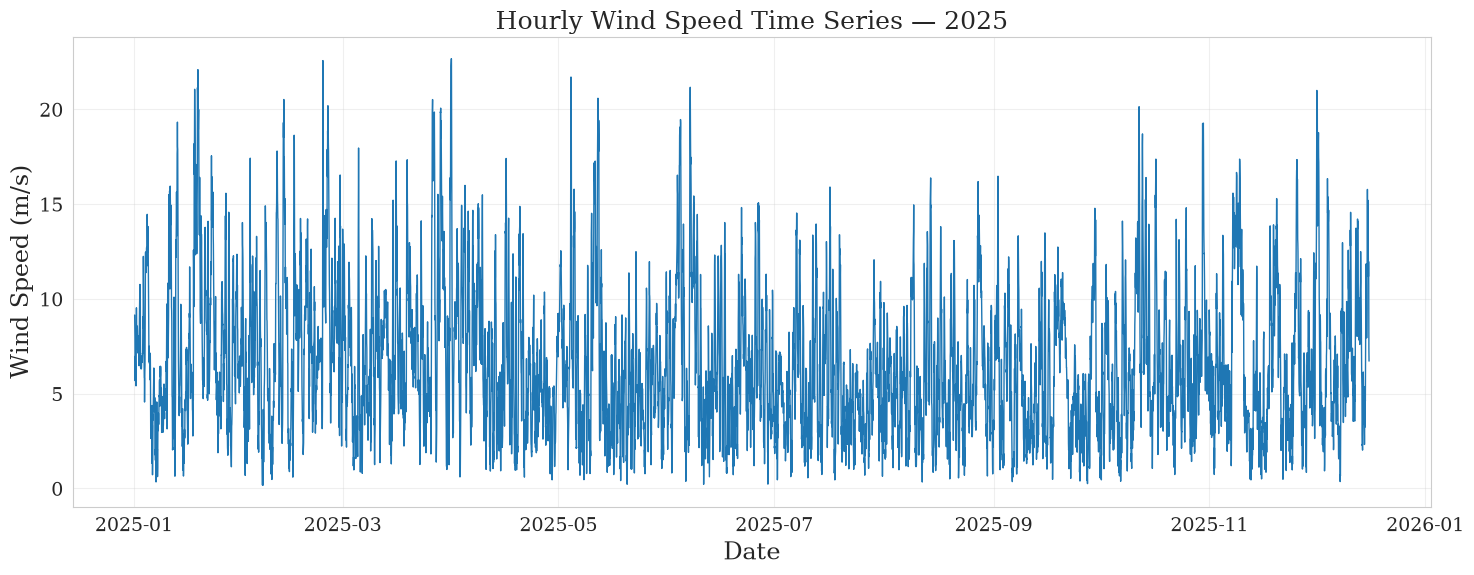

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# ============================================================
# 1. LOAD DATA
# ============================================================

df = pd.read_csv(WIND_FILE)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst observations:")
display(df.head())

print("\nData types:")
print(df.dtypes)

# ============================================================
# 2. CREATE DATETIME INDEX
# ============================================================

df["year"] = 2025

df["datetime"] = pd.to_datetime(
    dict(
        year=df["year"],
        month=df["month"],
        day=df["day"],
        hour=df["hour"]
    ),
    errors="coerce"
)

df = df.sort_values("datetime").reset_index(drop=True)

# ============================================================
# 3. BASIC DATA QUALITY AUDIT
# ============================================================

print("Date range:")
print(df["datetime"].min(), "to", df["datetime"].max())

print("\nTotal observations:")
print(len(df))

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate timestamps:")
print(df["datetime"].duplicated().sum())

print("\nWind speed descriptive statistics:")
print(df["windSpeed"].describe())

# ============================================================
# 4. CHECK TEMPORAL REGULARITY
# ============================================================

time_difference = df["datetime"].diff()

print("\nTimestamp interval distribution:")
print(time_difference.value_counts().head(10))

# ============================================================
# 5. CHECK PHYSICAL RANGE
# ============================================================

print("\nNegative wind-speed observations:")
print((df["windSpeed"] < 0).sum())

print("\nWind speeds above 30 m/s:")
print((df["windSpeed"] > 30).sum())

# ============================================================
# 6. SET DATETIME INDEX
# ============================================================

df = df.set_index("datetime")

# ============================================================
# 7. VISUALIZE FULL TIME SERIES
# ============================================================

plt.figure(figsize=(15, 6))

plt.plot(
    df.index,
    df["windSpeed"],
    linewidth=1
)

plt.title("Hourly Wind Speed Time Series — 2025")
plt.xlabel("Date")
plt.ylabel("Wind Speed (m/s)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


TRAIN
Observations: 5862
Period: 2025-01-01 05:00:00 to 2025-09-02 10:00:00

VALIDATION
Observations: 1256
Period: 2025-09-02 11:00:00 to 2025-10-24 18:00:00

TEST
Observations: 1257
Period: 2025-10-24 19:00:00 to 2025-12-16 03:00:00

PERSISTENCE BASELINE RESULTS
-----------------------------
MAE:   1.0374
RMSE:  1.3830
nRMSE: 0.0670
sMAPE: 19.83%
R²:    0.8805


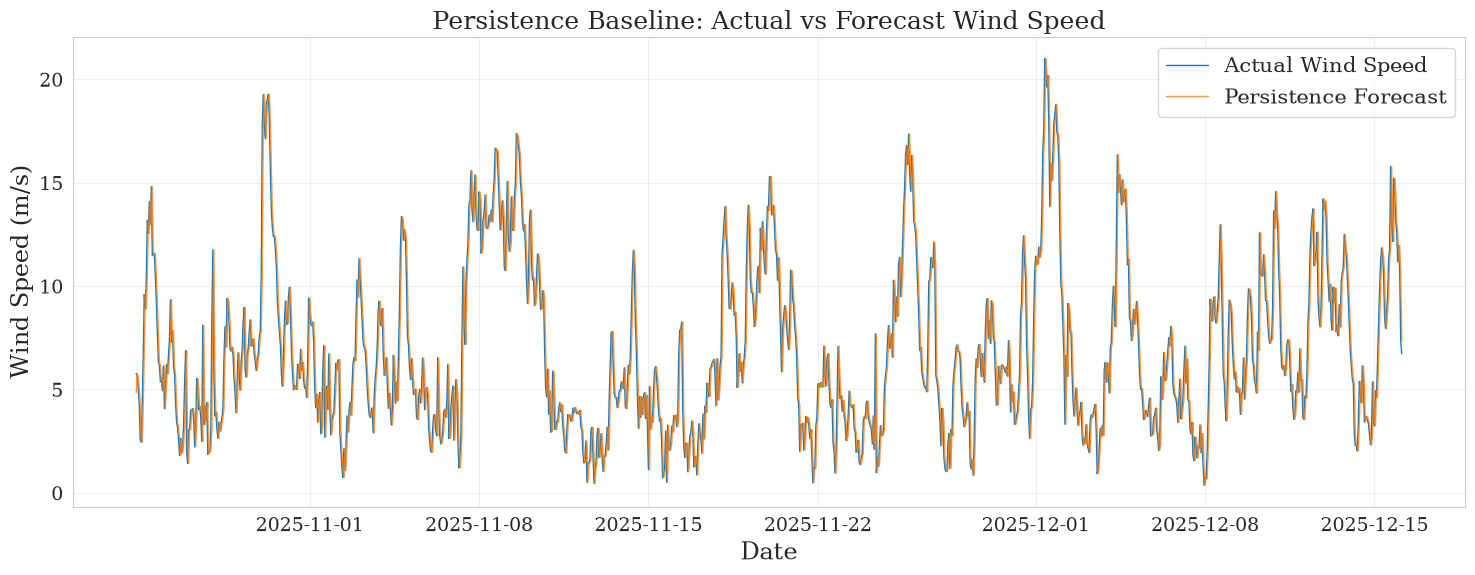

In [16]:
# ============================================================
# 1. CHRONOLOGICAL TRAIN / VALIDATION / TEST SPLIT
# ============================================================

n = len(df)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_df = df.iloc[:train_end].copy()
val_df = df.iloc[train_end:val_end].copy()
test_df = df.iloc[val_end:].copy()

print("TRAIN")
print("Observations:", len(train_df))
print("Period:", train_df.index.min(), "to", train_df.index.max())

print("\nVALIDATION")
print("Observations:", len(val_df))
print("Period:", val_df.index.min(), "to", val_df.index.max())

print("\nTEST")
print("Observations:", len(test_df))
print("Period:", test_df.index.min(), "to", test_df.index.max())


# ============================================================
# 2. PERSISTENCE FORECAST
# ============================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Persistence:
# Forecast at time t = observed wind speed at time t-1

y_true = test_df["windSpeed"].iloc[1:].values
y_pred = test_df["windSpeed"].shift(1).iloc[1:].values


# ============================================================
# 3. EVALUATION METRICS
# ============================================================

mae = mean_absolute_error(y_true, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_true, y_pred)
)

r2 = r2_score(y_true, y_pred)

# Normalized RMSE using observed range

nrmse = rmse / (
    y_true.max() - y_true.min()
)

# Symmetric MAPE

smape = (
    100 *
    np.mean(
        2 * np.abs(y_pred - y_true) /
        (
            np.abs(y_true) +
            np.abs(y_pred) +
            1e-8
        )
    )
)


# ============================================================
# 4. RESULTS
# ============================================================

print("\nPERSISTENCE BASELINE RESULTS")
print("-----------------------------")

print(f"MAE:   {mae:.4f}")
print(f"RMSE:  {rmse:.4f}")
print(f"nRMSE: {nrmse:.4f}")
print(f"sMAPE: {smape:.2f}%")
print(f"R²:    {r2:.4f}")


# ============================================================
# 5. VISUALIZATION
# ============================================================

plt.figure(figsize=(15, 6))

plt.plot(
    test_df.index[1:],
    y_true,
    label="Actual Wind Speed",
    linewidth=1
)

plt.plot(
    test_df.index[1:],
    y_pred,
    label="Persistence Forecast",
    linewidth=1,
    alpha=0.8
)

plt.title(
    "Persistence Baseline: Actual vs Forecast Wind Speed"
)

plt.xlabel("Date")
plt.ylabel("Wind Speed (m/s)")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [19]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler


# ============================================================
# EXPERIMENTAL CONFIGURATION
# ============================================================

CONTEXT_LENGTH = 168
FORECAST_HORIZON = 24

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15


# ============================================================
# EXTRACT WIND SPEED
# ============================================================

wind = df[["windSpeed"]].copy()

print("Total observations:", len(wind))
print("Start:", wind.index.min())
print("End:", wind.index.max())


# ============================================================
# CHRONOLOGICAL SPLIT BOUNDARIES
# ============================================================

n = len(wind)

train_end = int(n * TRAIN_RATIO)

val_end = int(
    n * (TRAIN_RATIO + VAL_RATIO)
)

print("\nSplit boundaries")

print("Train end index:", train_end)
print("Validation end index:", val_end)


# ============================================================
# FIT SCALER ONLY ON TRAINING DATA
# ============================================================

scaler = StandardScaler()

scaler.fit(
    wind.iloc[:train_end]
)


# ============================================================
# TRANSFORM COMPLETE SERIES
#
# This is safe because scaler was fitted only on training data.
# ============================================================

wind_scaled = scaler.transform(wind)


# ============================================================
# WINDOW CREATION FUNCTION
# ============================================================

def create_windows(
    data,
    context_length,
    forecast_horizon
):

    X = []
    y = []
    target_indices = []

    total_length = (
        context_length
        + forecast_horizon
    )

    for i in range(
        len(data) - total_length + 1
    ):

        # Historical context
        X.append(
            data[
                i:
                i + context_length
            ]
        )

        # Future 24-hour target
        y.append(
            data[
                i + context_length:
                i + total_length
            ]
        )

        # Store first target index
        target_indices.append(
            i + context_length
        )

    return (
        np.array(X),
        np.array(y),
        np.array(target_indices)
    )


# ============================================================
# CREATE ALL WINDOWS
# ============================================================

X, y, target_indices = create_windows(
    wind_scaled,
    CONTEXT_LENGTH,
    FORECAST_HORIZON
)


print("\nComplete window dataset")

print("X shape:", X.shape)
print("y shape:", y.shape)


# ============================================================
# ASSIGN WINDOWS CHRONOLOGICALLY
#
# Important:
# Assignment is based on target period,
# not merely the input starting position.
# ============================================================

train_mask = (
    target_indices
    + FORECAST_HORIZON
    <= train_end
)

val_mask = (
    (target_indices >= train_end)
    &
    (
        target_indices
        + FORECAST_HORIZON
        <= val_end
    )
)

test_mask = (
    target_indices >= val_end
)


# ============================================================
# CREATE FINAL DATASETS
# ============================================================

X_train = X[train_mask]
y_train = y[train_mask]

X_val = X[val_mask]
y_val = y[val_mask]

X_test = X[test_mask]
y_test = y[test_mask]


# ============================================================
# REMOVE FINAL SINGLETON DIMENSION FROM TARGET
# ============================================================

y_train = y_train.squeeze(-1)
y_val = y_val.squeeze(-1)
y_test = y_test.squeeze(-1)


# ============================================================
# FINAL SHAPES
# ============================================================

print("\nFINAL DATASETS")
print("----------------------------")

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print()

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print()

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

Total observations: 8375
Start: 2025-01-01 05:00:00
End: 2025-12-16 03:00:00

Split boundaries
Train end index: 5862
Validation end index: 7118

Complete window dataset
X shape: (8184, 168, 1)
y shape: (8184, 24, 1)

FINAL DATASETS
----------------------------
X_train: (5671, 168, 1)
y_train: (5671, 24)

X_val: (1233, 168, 1)
y_val: (1233, 24)

X_test: (1234, 168, 1)
y_test: (1234, 24)


In [20]:
# ============================================================
# FAIR 24-HOUR PERSISTENCE BASELINE
#
# Same X_test and y_test used by every model
# ============================================================

persistence_pred = np.repeat(
    X_test[:, -1, :],
    FORECAST_HORIZON,
    axis=1
)


# ============================================================
# INVERSE TRANSFORM
# ============================================================

y_test_original = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).reshape(y_test.shape)


persistence_original = scaler.inverse_transform(
    persistence_pred.reshape(-1, 1)
).reshape(persistence_pred.shape)


# ============================================================
# CHECK SHAPES
# ============================================================

print("Actual shape:")
print(y_test_original.shape)

print("\nPersistence prediction shape:")
print(persistence_original.shape)

Actual shape:
(1234, 24)

Persistence prediction shape:
(1234, 24)


In [21]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ============================================================
# METRIC FUNCTION
# ============================================================

def calculate_metrics(y_true, y_pred):
    mae = mean_absolute_error(
        y_true.flatten(),
        y_pred.flatten()
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true.flatten(),
            y_pred.flatten()
        )
    )

    observed_range = (
        y_true.max() - y_true.min()
    )

    nrmse = (
        rmse / observed_range
        if observed_range > 0
        else np.nan
    )

    smape = (
        100
        * np.mean(
            2 * np.abs(y_pred - y_true)
            / (
                np.abs(y_true)
                + np.abs(y_pred)
                + 1e-8
            )
        )
    )

    r2 = r2_score(
        y_true.flatten(),
        y_pred.flatten()
    )

    return {
        "MAE": mae,
        "RMSE": rmse,
        "nRMSE": nrmse,
        "sMAPE (%)": smape,
        "R2": r2
    }


# ============================================================
# OVERALL 24-HOUR PERFORMANCE
# ============================================================

overall_metrics = calculate_metrics(
    y_test_original,
    persistence_original
)

print("OVERALL 24-HOUR PERSISTENCE PERFORMANCE")
print("---------------------------------------")

for metric, value in overall_metrics.items():
    print(f"{metric}: {value:.4f}")


# ============================================================
# HORIZON-SPECIFIC PERFORMANCE
# ============================================================

selected_horizons = [1, 6, 12, 24]

horizon_results = []

for horizon in selected_horizons:

    # Python index is horizon - 1
    idx = horizon - 1

    y_true_h = y_test_original[:, idx]
    y_pred_h = persistence_original[:, idx]

    metrics_h = calculate_metrics(
        y_true_h.reshape(-1, 1),
        y_pred_h.reshape(-1, 1)
    )

    metrics_h["Horizon"] = f"{horizon}h"

    horizon_results.append(metrics_h)


horizon_results_df = pd.DataFrame(
    horizon_results
)[
    [
        "Horizon",
        "MAE",
        "RMSE",
        "nRMSE",
        "sMAPE (%)",
        "R2"
    ]
]

print("\nHORIZON-SPECIFIC PERSISTENCE PERFORMANCE")
print("----------------------------------------")

display(
    horizon_results_df.round(4)
)

OVERALL 24-HOUR PERSISTENCE PERFORMANCE
---------------------------------------
MAE: 3.1211
RMSE: 4.1694
nRMSE: 0.2021
sMAPE (%): 49.2601
R2: -0.0922

HORIZON-SPECIFIC PERSISTENCE PERFORMANCE
----------------------------------------


,Horizon,MAE,RMSE,nRMSE,sMAPE (%),R2
0,1h,1.0300,1.3757,0.0667,19.9489,0.8805
1,6h,2.6784,3.4799,0.1686,44.0489,0.2380
2,12h,3.2905,4.2781,0.2073,51.6569,-0.1513
3,24h,4.0141,5.1769,0.2509,60.5409,-0.6784


In [49]:
import gc
import time
import numpy as np
import pandas as pd
import torch

from chronos import Chronos2Pipeline

In [50]:
# ============================================================
# DEVICE CONFIGURATION
# ============================================================

if torch.cuda.is_available():
    DEVICE_MAP = "cuda"
    print("Using GPU:", torch.cuda.get_device_name(0))
else:
    DEVICE_MAP = "cpu"
    print("Using CPU")

print("PyTorch version:", torch.__version__)

Using CPU
PyTorch version: 2.13.0


In [51]:
# ============================================================
# INVERSE TRANSFORM X_TEST TO ORIGINAL SCALE
# ============================================================

X_test_original = scaler.inverse_transform(
    X_test.reshape(-1, 1)
).reshape(X_test.shape)

print("Scaled X_test shape:", X_test.shape)
print("Original X_test shape:", X_test_original.shape)
print("Actual y_test shape:", y_test_original.shape)

print("\nWind-speed range in X_test_original:")
print(
    f"Minimum: {X_test_original.min():.4f} m/s"
)
print(
    f"Maximum: {X_test_original.max():.4f} m/s"
)

Scaled X_test shape: (1234, 168, 1)
Original X_test shape: (1234, 168, 1)
Actual y_test shape: (1234, 24)

Wind-speed range in X_test_original:
Minimum: 0.3633 m/s
Maximum: 20.9982 m/s


In [52]:
# ============================================================
# BUILD CHRONOS-2 CONTEXT DATAFRAME
# ============================================================

N_TEST_WINDOWS = X_test_original.shape[0]
CONTEXT_LENGTH = X_test_original.shape[1]

# Chronos needs regular timestamps.
# These timestamps represent relative hourly positions within
# each forecast window.
context_timestamps = pd.date_range(
    start="2025-01-01 00:00:00",
    periods=CONTEXT_LENGTH,
    freq="h"
)

context_frames = []

for series_id in range(N_TEST_WINDOWS):

    series_values = X_test_original[
        series_id,
        :,
        0
    ]

    series_df = pd.DataFrame({
        "series_id": series_id,
        "timestamp": context_timestamps,
        "target": series_values
    })

    context_frames.append(series_df)


chronos_context_df = pd.concat(
    context_frames,
    ignore_index=True
)

print("Chronos context dataframe shape:")
print(chronos_context_df.shape)

print("\nNumber of series:")
print(chronos_context_df["series_id"].nunique())

print("\nObservations per series:")
print(
    chronos_context_df
    .groupby("series_id")
    .size()
    .describe()
)

display(chronos_context_df.head())

Chronos context dataframe shape:
(207312, 3)

Number of series:
1234

Observations per series:
count    1234.0
mean      168.0
std         0.0
min       168.0
25%       168.0
50%       168.0
75%       168.0
max       168.0
dtype: float64


,series_id,timestamp,target
0,0,2025-01-01 00:00:00,9.418833
1,0,2025-01-01 01:00:00,8.778333
2,0,2025-01-01 02:00:00,8.401333
3,0,2025-01-01 03:00:00,7.986667
4,0,2025-01-01 04:00:00,7.085500


In [53]:
# ============================================================
# VALIDATE CHRONOS INPUT
# ============================================================

assert chronos_context_df["target"].notna().all()
assert chronos_context_df["series_id"].nunique() == len(X_test_original)

observations_per_series = (
    chronos_context_df
    .groupby("series_id")
    .size()
)

assert (
    observations_per_series == CONTEXT_LENGTH
).all()

print("Chronos-2 input validation passed.")

Chronos-2 input validation passed.


In [54]:
# ============================================================
# LOAD PRETRAINED CHRONOS-2
# ============================================================

MODEL_ID = "amazon/chronos-2"

load_start = time.time()

chronos_pipeline = Chronos2Pipeline.from_pretrained(
    MODEL_ID,
    device_map=DEVICE_MAP
)

load_seconds = time.time() - load_start

print(
    f"Chronos-2 loaded in {load_seconds:.2f} seconds."
)

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

Chronos-2 loaded in 3.26 seconds.


In [55]:
# ============================================================
# CHRONOS-2 ZERO-SHOT FORECAST
# ============================================================

QUANTILE_LEVELS = [0.1, 0.5, 0.9]

forecast_start = time.time()

chronos_forecast_df = chronos_pipeline.predict_df(
    chronos_context_df,
    prediction_length=FORECAST_HORIZON,
    quantile_levels=QUANTILE_LEVELS,
    id_column="series_id",
    timestamp_column="timestamp",
    target="target"
)

forecast_seconds = time.time() - forecast_start

print(
    f"Forecasting completed in {forecast_seconds:.2f} seconds."
)

print("\nForecast dataframe shape:")
print(chronos_forecast_df.shape)

print("\nForecast columns:")
print(chronos_forecast_df.columns.tolist())

display(chronos_forecast_df.head(30))

Forecasting completed in 17.61 seconds.

Forecast dataframe shape:
(29616, 7)

Forecast columns:
['series_id', 'timestamp', 'target_name', 'predictions', '0.1', '0.5', '0.9']


,series_id,timestamp,target_name,predictions,0.1,0.5,0.9
0,0,2025-01-08 00:00:00,target,4.457973,3.362084,4.457973,5.964355
1,0,2025-01-08 01:00:00,target,4.257946,2.752211,4.257946,6.224644
2,0,2025-01-08 02:00:00,target,3.955451,2.337931,3.955451,6.232226
3,0,2025-01-08 03:00:00,target,3.704212,2.006985,3.704212,6.132115
4,0,2025-01-08 04:00:00,target,3.570949,1.881363,3.570949,6.206685
5,0,2025-01-08 05:00:00,target,3.610372,1.807114,3.610372,6.454010
6,0,2025-01-08 06:00:00,target,3.750648,1.769189,3.750648,6.800110
7,0,2025-01-08 07:00:00,target,3.922721,1.816718,3.922721,7.363011
8,0,2025-01-08 08:00:00,target,4.094484,1.889579,4.094484,7.720732
9,0,2025-01-08 09:00:00,target,4.180304,1.951425,4.180304,8.262135


In [56]:
# ============================================================
# VALIDATE FORECAST OUTPUT
# ============================================================

print("Number of forecast series:")
print(
    chronos_forecast_df["series_id"].nunique()
)

print("\nForecast rows per series:")
print(
    chronos_forecast_df
    .groupby("series_id")
    .size()
    .describe()
)

assert (
    chronos_forecast_df["series_id"].nunique()
    == N_TEST_WINDOWS
)

assert (
    chronos_forecast_df
    .groupby("series_id")
    .size()
    == FORECAST_HORIZON
).all()

print("\nChronos-2 forecast validation passed.")

Number of forecast series:
1234

Forecast rows per series:
count    1234.0
mean       24.0
std         0.0
min        24.0
25%        24.0
50%        24.0
75%        24.0
max        24.0
dtype: float64

Chronos-2 forecast validation passed.


In [57]:
# ============================================================
# SORT FORECASTS
# ============================================================

chronos_forecast_df = (
    chronos_forecast_df
    .sort_values(
        ["series_id", "timestamp"]
    )
    .reset_index(drop=True)
)

In [58]:
# ============================================================
# EXTRACT POINT FORECASTS
# ============================================================

if "predictions" not in chronos_forecast_df.columns:
    raise KeyError(
        "The Chronos output does not contain a "
        "'predictions' column. Available columns: "
        f"{chronos_forecast_df.columns.tolist()}"
    )

chronos_point_predictions = (
    chronos_forecast_df["predictions"]
    .to_numpy(dtype=np.float32)
    .reshape(
        N_TEST_WINDOWS,
        FORECAST_HORIZON
    )
)

print(
    "Chronos point prediction shape:",
    chronos_point_predictions.shape
)

print(
    "Actual test target shape:",
    y_test_original.shape
)

Chronos point prediction shape: (1234, 24)
Actual test target shape: (1234, 24)


In [59]:
# ============================================================
# EXTRACT QUANTILE FORECASTS
# ============================================================

def find_quantile_column(
    dataframe,
    quantile
):
    """
    Find a quantile column despite possible naming differences,
    such as '0.1', 0.1, or 'q0.1'.
    """

    possible_names = [
        str(quantile),
        quantile,
        f"q{quantile}",
        f"quantile_{quantile}"
    ]

    for name in possible_names:
        if name in dataframe.columns:
            return name

    raise KeyError(
        f"Could not find quantile {quantile}. "
        f"Available columns: {dataframe.columns.tolist()}"
    )


q10_column = find_quantile_column(
    chronos_forecast_df,
    0.1
)

q50_column = find_quantile_column(
    chronos_forecast_df,
    0.5
)

q90_column = find_quantile_column(
    chronos_forecast_df,
    0.9
)


chronos_q10 = (
    chronos_forecast_df[q10_column]
    .to_numpy(dtype=np.float32)
    .reshape(
        N_TEST_WINDOWS,
        FORECAST_HORIZON
    )
)

chronos_q50 = (
    chronos_forecast_df[q50_column]
    .to_numpy(dtype=np.float32)
    .reshape(
        N_TEST_WINDOWS,
        FORECAST_HORIZON
    )
)

chronos_q90 = (
    chronos_forecast_df[q90_column]
    .to_numpy(dtype=np.float32)
    .reshape(
        N_TEST_WINDOWS,
        FORECAST_HORIZON
    )
)


print("P10 shape:", chronos_q10.shape)
print("P50 shape:", chronos_q50.shape)
print("P90 shape:", chronos_q90.shape)

P10 shape: (1234, 24)
P50 shape: (1234, 24)
P90 shape: (1234, 24)


In [60]:
# ============================================================
# QUANTILE CONSISTENCY CHECK
# ============================================================

q10_q50_violations = np.sum(
    chronos_q10 > chronos_q50
)

q50_q90_violations = np.sum(
    chronos_q50 > chronos_q90
)

print(
    "P10 > P50 violations:",
    q10_q50_violations
)

print(
    "P50 > P90 violations:",
    q50_q90_violations
)

P10 > P50 violations: 0
P50 > P90 violations: 0


In [61]:
# ============================================================
# PHYSICAL CONSTRAINT: WIND SPEED >= 0
# ============================================================

chronos_point_predictions = np.clip(
    chronos_point_predictions,
    a_min=0.0,
    a_max=None
)

chronos_q10 = np.clip(
    chronos_q10,
    a_min=0.0,
    a_max=None
)

chronos_q50 = np.clip(
    chronos_q50,
    a_min=0.0,
    a_max=None
)

chronos_q90 = np.clip(
    chronos_q90,
    a_min=0.0,
    a_max=None
)

In [62]:
raw_negative_count = np.sum(
    chronos_forecast_df["predictions"].to_numpy() < 0
)

print(
    "Negative raw point forecasts before clipping:",
    raw_negative_count
)

Negative raw point forecasts before clipping: 0


In [63]:
# ============================================================
# OVERALL CHRONOS-2 POINT-FORECAST PERFORMANCE
# ============================================================

chronos_overall = calculate_metrics(
    y_test_original,
    chronos_point_predictions
)

print("\nOVERALL CHRONOS-2 PERFORMANCE")
print("-----------------------------")

for metric, value in chronos_overall.items():
    print(f"{metric}: {value:.4f}")


OVERALL CHRONOS-2 PERFORMANCE
-----------------------------
MAE: 2.8458
RMSE: 3.8387
nRMSE: 0.1860
sMAPE (%): 45.1917
R2: 0.0742


In [64]:
# ============================================================
# HORIZON-SPECIFIC CHRONOS-2 PERFORMANCE
# ============================================================

chronos_horizon_results = []

for horizon in selected_horizons:

    idx = horizon - 1

    y_true_h = y_test_original[:, idx]

    y_pred_h = chronos_point_predictions[:, idx]

    metrics_h = calculate_metrics(
        y_true_h.reshape(-1, 1),
        y_pred_h.reshape(-1, 1)
    )

    metrics_h["Horizon"] = f"{horizon}h"

    chronos_horizon_results.append(
        metrics_h
    )


chronos_horizon_df = pd.DataFrame(
    chronos_horizon_results
)[
    [
        "Horizon",
        "MAE",
        "RMSE",
        "nRMSE",
        "sMAPE (%)",
        "R2"
    ]
]

print("\nHORIZON-SPECIFIC CHRONOS-2 PERFORMANCE")
print("---------------------------------------")

display(
    chronos_horizon_df.round(4)
)


HORIZON-SPECIFIC CHRONOS-2 PERFORMANCE
---------------------------------------


,Horizon,MAE,RMSE,nRMSE,sMAPE (%),R2
0,1h,1.0449,1.4062,0.0681,19.7283,0.8751
1,6h,2.5936,3.3926,0.1644,41.8921,0.2758
2,12h,2.9752,3.9406,0.1910,46.9939,0.0232
3,24h,3.4806,4.5800,0.2220,53.6296,-0.3137


In [65]:
# ============================================================
# CHRONOS-2 P50 SECONDARY PERFORMANCE
# ============================================================

chronos_p50_overall = calculate_metrics(
    y_test_original,
    chronos_q50
)

print("\nOVERALL CHRONOS-2 P50 PERFORMANCE")
print("---------------------------------")

for metric, value in chronos_p50_overall.items():
    print(f"{metric}: {value:.4f}")


OVERALL CHRONOS-2 P50 PERFORMANCE
---------------------------------
MAE: 2.8458
RMSE: 3.8387
nRMSE: 0.1860
sMAPE (%): 45.1917
R2: 0.0742


In [66]:
# ============================================================
# OVERALL MODEL COMPARISON
# ============================================================

overall_model_comparison = pd.DataFrame([

    {
        "Model": "Constant Persistence",
        **overall_metrics
    },

    {
        "Model": "Daily Seasonal Persistence",
        **seasonal_overall_metrics
    },

    {
        "Model": "CNN-LSTM V2",
        **cnn_lstm_v2_overall
    },

    {
        "Model": "PatchTST",
        **patchtst_overall
    },

    {
        "Model": "Chronos-2 Zero-Shot",
        **chronos_overall
    }

])


overall_model_comparison = overall_model_comparison[
    [
        "Model",
        "MAE",
        "RMSE",
        "nRMSE",
        "sMAPE (%)",
        "R2"
    ]
]


print("OVERALL MODEL COMPARISON")
print("------------------------")

display(
    overall_model_comparison.round(4)
)

OVERALL MODEL COMPARISON
------------------------


,Model,MAE,RMSE,nRMSE,sMAPE (%),R2
0,Constant Persistence,3.1211,4.1694,0.2021,49.2601,-0.0922
1,Daily Seasonal Persistence,3.9977,5.1515,0.2496,60.3535,-0.6673
2,CNN-LSTM V2,2.7838,3.4988,0.1696,43.7756,0.2309
3,PatchTST,2.9823,3.7709,0.1827,46.2980,0.1066
4,Chronos-2 Zero-Shot,2.8458,3.8387,0.1860,45.1917,0.0742


In [67]:
# ============================================================
# HORIZON-SPECIFIC MODEL COMPARISON
# ============================================================

comparison_by_horizon = pd.concat(
    [
        horizon_results_df.assign(
            Model="Constant Persistence"
        ),

        seasonal_horizon_df.assign(
            Model="Daily Seasonal Persistence"
        ),

        cnn_lstm_v2_horizon_df.assign(
            Model="CNN-LSTM V2"
        ),

        patchtst_horizon_df.assign(
            Model="PatchTST"
        ),

        chronos_horizon_df.assign(
            Model="Chronos-2 Zero-Shot"
        )
    ],
    ignore_index=True
)


comparison_by_horizon = comparison_by_horizon[
    [
        "Model",
        "Horizon",
        "MAE",
        "RMSE",
        "nRMSE",
        "sMAPE (%)",
        "R2"
    ]
]


display(
    comparison_by_horizon.round(4)
)

,Model,Horizon,MAE,RMSE,nRMSE,sMAPE (%),R2
0,Constant Persistence,1h,1.0300,1.3757,0.0667,19.9489,0.8805
1,Constant Persistence,6h,2.6784,3.4799,0.1686,44.0489,0.2380
2,Constant Persistence,12h,3.2905,4.2781,0.2073,51.6569,-0.1513
3,Constant Persistence,24h,4.0141,5.1769,0.2509,60.5409,-0.6784
4,Daily Seasonal Persistence,1h,3.9599,5.1140,0.2478,59.8875,-0.6519
5,Daily Seasonal Persistence,6h,3.9891,5.1391,0.2490,60.3046,-0.6618
6,Daily Seasonal Persistence,12h,3.9974,5.1451,0.2493,60.3258,-0.6653
7,Daily Seasonal Persistence,24h,4.0141,5.1769,0.2509,60.5409,-0.6784
8,CNN-LSTM V2,1h,1.5070,1.9226,0.0932,27.6465,0.7665
9,CNN-LSTM V2,6h,2.4956,3.1614,0.1532,40.2461,0.3711


In [68]:
# ============================================================
# CHRONOS-2 IMPROVEMENT OVER CONSTANT PERSISTENCE
# ============================================================

chronos_improvement_rows = []

for horizon in selected_horizons:

    horizon_label = f"{horizon}h"

    persistence_row = horizon_results_df[
        horizon_results_df["Horizon"] == horizon_label
    ].iloc[0]

    chronos_row = chronos_horizon_df[
        chronos_horizon_df["Horizon"] == horizon_label
    ].iloc[0]

    mae_improvement = (
        (
            persistence_row["MAE"]
            - chronos_row["MAE"]
        )
        / persistence_row["MAE"]
        * 100
    )

    rmse_improvement = (
        (
            persistence_row["RMSE"]
            - chronos_row["RMSE"]
        )
        / persistence_row["RMSE"]
        * 100
    )

    chronos_improvement_rows.append({
        "Horizon": horizon_label,
        "MAE Improvement vs Persistence (%)":
            mae_improvement,
        "RMSE Improvement vs Persistence (%)":
            rmse_improvement
    })


chronos_improvement_df = pd.DataFrame(
    chronos_improvement_rows
)

display(
    chronos_improvement_df.round(2)
)

,Horizon,MAE Improvement vs Persistence (%),RMSE Improvement vs Persistence (%)
0,1h,-1.45,-2.22
1,6h,3.17,2.51
2,12h,9.58,7.89
3,24h,13.29,11.53


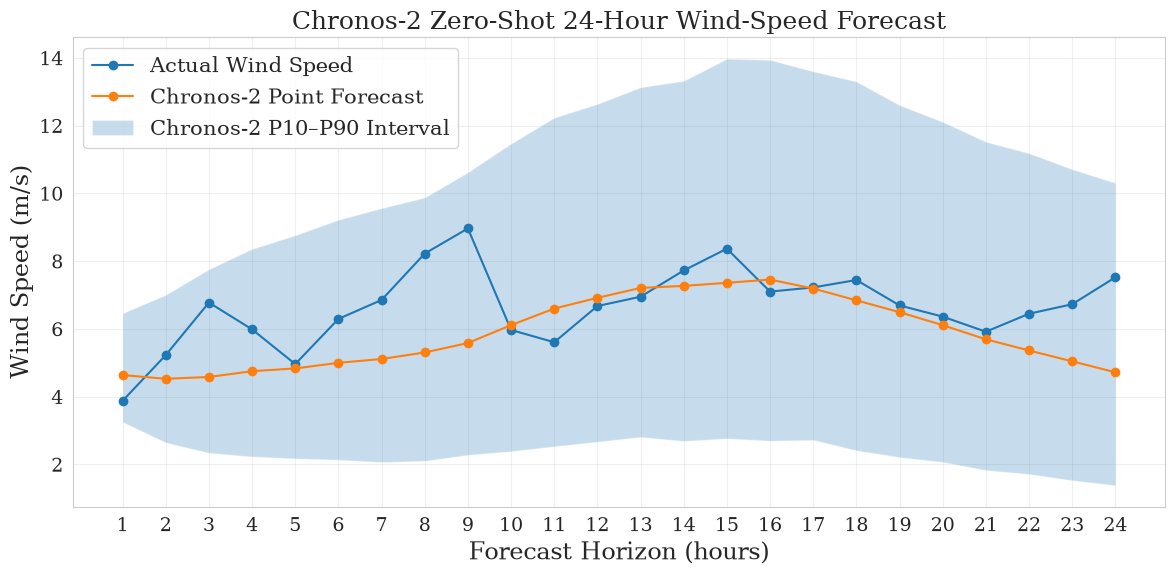

In [69]:
import matplotlib.pyplot as plt

# Select one forecast window
example_index = 100

hours_ahead = np.arange(
    1,
    FORECAST_HORIZON + 1
)

plt.figure(figsize=(12, 6))

plt.plot(
    hours_ahead,
    y_test_original[example_index],
    marker="o",
    label="Actual Wind Speed"
)

plt.plot(
    hours_ahead,
    chronos_point_predictions[example_index],
    marker="o",
    label="Chronos-2 Point Forecast"
)

plt.fill_between(
    hours_ahead,
    chronos_q10[example_index],
    chronos_q90[example_index],
    alpha=0.25,
    label="Chronos-2 P10–P90 Interval"
)

plt.title(
    "Chronos-2 Zero-Shot 24-Hour Wind-Speed Forecast"
)

plt.xlabel("Forecast Horizon (hours)")
plt.ylabel("Wind Speed (m/s)")

plt.xticks(hours_ahead)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [70]:
chronos_q10
chronos_q50
chronos_q90

array([[ 5.9643555,  6.224644 ,  6.232226 , ..., 12.289158 , 12.091189 ,
        11.654535 ],
       [ 6.1434917,  6.2007227,  6.2997084, ..., 11.787269 , 11.420621 ,
        10.957243 ],
       [ 6.738252 ,  6.838389 ,  7.038859 , ..., 11.5171995, 11.025717 ,
        10.6748295],
       ...,
       [ 6.0055227,  6.912873 ,  7.391581 , ..., 10.846955 , 10.932461 ,
        10.792563 ],
       [ 5.4989786,  6.0753613,  6.662848 , ..., 10.2604265, 10.150539 ,
        10.041506 ],
       [ 7.7587137,  8.851174 ,  9.317912 , ..., 11.749807 , 11.774399 ,
        11.861278 ]], shape=(1234, 24), dtype=float32)

In [71]:
# ============================================================
# PROBABILISTIC FORECAST EVALUATION
# CHRONOS-2
# ============================================================

import numpy as np
import pandas as pd


# ============================================================
# PINBALL LOSS
# ============================================================

def pinball_loss(y_true, y_pred, quantile):

    error = y_true - y_pred

    return np.mean(
        np.maximum(
            quantile * error,
            (quantile - 1) * error
        )
    )


pinball_q10 = pinball_loss(
    y_test_original,
    chronos_q10,
    0.10
)

pinball_q50 = pinball_loss(
    y_test_original,
    chronos_q50,
    0.50
)

pinball_q90 = pinball_loss(
    y_test_original,
    chronos_q90,
    0.90
)


print("PINBALL LOSS")
print("-----------------------------")

print(f"P10: {pinball_q10:.4f}")
print(f"P50: {pinball_q50:.4f}")
print(f"P90: {pinball_q90:.4f}")

PINBALL LOSS
-----------------------------
P10: 0.5215
P50: 1.4229
P90: 0.8097


In [72]:
# ============================================================
# PREDICTION INTERVAL COVERAGE PROBABILITY
# ============================================================

inside_interval = (
    (y_test_original >= chronos_q10)
    &
    (y_test_original <= chronos_q90)
)


picp = np.mean(
    inside_interval
)


print("\nPREDICTION INTERVAL COVERAGE")
print("-----------------------------")

print(
    f"Nominal coverage: 80.00%"
)

print(
    f"Empirical PICP: {picp * 100:.2f}%"
)


PREDICTION INTERVAL COVERAGE
-----------------------------
Nominal coverage: 80.00%
Empirical PICP: 75.68%


In [73]:
# ============================================================
# MEAN PREDICTION INTERVAL WIDTH
# ============================================================

interval_width = (
    chronos_q90 - chronos_q10
)


mpiw = np.mean(
    interval_width
)


print("\nMEAN PREDICTION INTERVAL WIDTH")
print("-----------------------------")

print(
    f"MPIW: {mpiw:.4f} m/s"
)


MEAN PREDICTION INTERVAL WIDTH
-----------------------------
MPIW: 8.2930 m/s


In [74]:
# ============================================================
# NORMALIZED INTERVAL WIDTH
# ============================================================

observed_range = (
    y_test_original.max()
    -
    y_test_original.min()
)


pinaw = (
    mpiw / observed_range
)


print("\nNORMALIZED INTERVAL WIDTH")
print("-----------------------------")

print(
    f"PINAW: {pinaw:.4f}"
)


NORMALIZED INTERVAL WIDTH
-----------------------------
PINAW: 0.4019


In [75]:
# ============================================================
# INTERVAL SCORE
#
# P10-P90 = 80% prediction interval
# alpha = 0.20
# ============================================================

def interval_score(
    y_true,
    lower,
    upper,
    alpha=0.20
):

    width = upper - lower

    lower_penalty = (
        (2 / alpha)
        *
        (lower - y_true)
        *
        (y_true < lower)
    )

    upper_penalty = (
        (2 / alpha)
        *
        (y_true - upper)
        *
        (y_true > upper)
    )

    score = (
        width
        +
        lower_penalty
        +
        upper_penalty
    )

    return np.mean(score)


chronos_interval_score = interval_score(
    y_test_original,
    chronos_q10,
    chronos_q90,
    alpha=0.20
)


print("\nINTERVAL SCORE")
print("-----------------------------")

print(
    f"80% Interval Score: "
    f"{chronos_interval_score:.4f}"
)


INTERVAL SCORE
-----------------------------
80% Interval Score: 13.3122


In [76]:
# ============================================================
# PROBABILISTIC PERFORMANCE BY HORIZON
# ============================================================

probabilistic_horizon_results = []


for horizon in selected_horizons:

    idx = horizon - 1

    y_true_h = (
        y_test_original[:, idx]
    )

    q10_h = (
        chronos_q10[:, idx]
    )

    q50_h = (
        chronos_q50[:, idx]
    )

    q90_h = (
        chronos_q90[:, idx]
    )


    # Pinball losses

    pb10 = pinball_loss(
        y_true_h,
        q10_h,
        0.10
    )

    pb50 = pinball_loss(
        y_true_h,
        q50_h,
        0.50
    )

    pb90 = pinball_loss(
        y_true_h,
        q90_h,
        0.90
    )


    # Coverage

    coverage = np.mean(
        (y_true_h >= q10_h)
        &
        (y_true_h <= q90_h)
    )


    # Interval width

    width = np.mean(
        q90_h - q10_h
    )


    # Interval score

    score = interval_score(
        y_true_h,
        q10_h,
        q90_h,
        alpha=0.20
    )


    probabilistic_horizon_results.append({

        "Horizon": f"{horizon}h",

        "Pinball P10": pb10,

        "Pinball P50": pb50,

        "Pinball P90": pb90,

        "PICP (%)":
            coverage * 100,

        "MPIW":
            width,

        "Interval Score":
            score

    })


probabilistic_horizon_df = pd.DataFrame(
    probabilistic_horizon_results
)


display(
    probabilistic_horizon_df.round(4)
)

,Horizon,Pinball P10,Pinball P50,Pinball P90,PICP (%),MPIW,Interval Score
0,1h,0.2240,0.5224,0.2708,77.1475,3.1262,4.9474
1,6h,0.4920,1.2968,0.7145,73.4198,7.1866,12.0652
2,12h,0.5618,1.4876,0.8604,76.2561,8.8683,14.2219
3,24h,0.6046,1.7403,1.0065,75.7699,10.1439,16.1110


In [77]:
# ============================================================
# RECOVER VALIDATION INPUTS ON ORIGINAL SCALE
# ============================================================

X_val_original = scaler.inverse_transform(
    X_val.reshape(-1, 1)
).reshape(X_val.shape)


y_val_original = scaler.inverse_transform(
    y_val.reshape(-1, 1)
).reshape(y_val.shape)


print("X_val_original shape:", X_val_original.shape)
print("y_val_original shape:", y_val_original.shape)

X_val_original shape: (1233, 168, 1)
y_val_original shape: (1233, 24)


In [78]:
# ============================================================
# CREATE CHRONOS VALIDATION DATAFRAME
# ============================================================

N_VAL_WINDOWS = X_val_original.shape[0]

val_context_frames = []


for series_id in range(N_VAL_WINDOWS):

    series_values = X_val_original[
        series_id,
        :,
        0
    ]

    series_df = pd.DataFrame({

        "series_id": series_id,

        "timestamp": context_timestamps,

        "target": series_values

    })

    val_context_frames.append(
        series_df
    )


chronos_val_context_df = pd.concat(
    val_context_frames,
    ignore_index=True
)


print(
    "Validation dataframe shape:",
    chronos_val_context_df.shape
)

print(
    "Validation series:",
    chronos_val_context_df[
        "series_id"
    ].nunique()
)

Validation dataframe shape: (207144, 3)
Validation series: 1233


In [79]:
# ============================================================
# CHRONOS-2 VALIDATION FORECASTS
# ============================================================

chronos_val_forecast_df = chronos_pipeline.predict_df(

    chronos_val_context_df,

    prediction_length=FORECAST_HORIZON,

    quantile_levels=[
        0.1,
        0.5,
        0.9
    ],

    id_column="series_id",

    timestamp_column="timestamp",

    target="target"
)


chronos_val_forecast_df = (

    chronos_val_forecast_df

    .sort_values(
        [
            "series_id",
            "timestamp"
        ]
    )

    .reset_index(drop=True)

)


print(
    chronos_val_forecast_df.columns
)

Index(['series_id', 'timestamp', 'target_name', 'predictions', '0.1', '0.5',
       '0.9'],
      dtype='str')


In [80]:
# ============================================================
# IDENTIFY QUANTILE COLUMNS
# ============================================================

val_q10_column = find_quantile_column(
    chronos_val_forecast_df,
    0.1
)

val_q50_column = find_quantile_column(
    chronos_val_forecast_df,
    0.5
)

val_q90_column = find_quantile_column(
    chronos_val_forecast_df,
    0.9
)


# ============================================================
# RESHAPE QUANTILES
# ============================================================

chronos_val_q10 = (

    chronos_val_forecast_df[
        val_q10_column
    ]

    .to_numpy(
        dtype=np.float32
    )

    .reshape(
        N_VAL_WINDOWS,
        FORECAST_HORIZON
    )

)


chronos_val_q50 = (

    chronos_val_forecast_df[
        val_q50_column
    ]

    .to_numpy(
        dtype=np.float32
    )

    .reshape(
        N_VAL_WINDOWS,
        FORECAST_HORIZON
    )

)


chronos_val_q90 = (

    chronos_val_forecast_df[
        val_q90_column
    ]

    .to_numpy(
        dtype=np.float32
    )

    .reshape(
        N_VAL_WINDOWS,
        FORECAST_HORIZON
    )

)


print(
    "Validation Q10:",
    chronos_val_q10.shape
)

print(
    "Validation Q50:",
    chronos_val_q50.shape
)

print(
    "Validation Q90:",
    chronos_val_q90.shape
)

Validation Q10: (1233, 24)
Validation Q50: (1233, 24)
Validation Q90: (1233, 24)


In [81]:
# ============================================================
# HORIZON-WISE CONFORMAL SCORES
# ============================================================

ALPHA = 0.20


conformity_scores = np.maximum(

    chronos_val_q10
    -
    y_val_original,

    y_val_original
    -
    chronos_val_q90

)


print(
    "Conformity score shape:",
    conformity_scores.shape
)

Conformity score shape: (1233, 24)


In [82]:
conformity_scores = np.maximum(
    conformity_scores,
    0.0
)

In [83]:
# ============================================================
# FINITE-SAMPLE CONFORMAL QUANTILES
# ============================================================

n_calibration = conformity_scores.shape[0]


quantile_level = (

    np.ceil(
        (n_calibration + 1)
        *
        (1 - ALPHA)
    )

    /

    n_calibration

)


quantile_level = min(
    quantile_level,
    1.0
)


print(
    "Calibration samples:",
    n_calibration
)

print(
    "Finite-sample quantile level:",
    quantile_level
)

Calibration samples: 1233
Finite-sample quantile level: 0.8012976480129764


In [84]:
conformal_corrections = np.quantile(

    conformity_scores,

    quantile_level,

    axis=0,

    method="higher"

)


print(
    "Conformal correction shape:",
    conformal_corrections.shape
)


correction_df = pd.DataFrame({

    "Horizon":
        np.arange(
            1,
            FORECAST_HORIZON + 1
        ),

    "Conformal Correction":
        conformal_corrections

})


display(
    correction_df.round(4)
)

Conformal correction shape: (24,)


,Horizon,Conformal Correction
0,1,0.0888
1,2,0.1912
2,3,0.1649
3,4,0.2867
4,5,0.3405
5,6,0.4269
6,7,0.5308
7,8,0.5332
8,9,0.6755
9,10,0.5809


In [85]:
# ============================================================
# CONFORMALLY CALIBRATED TEST INTERVALS
# ============================================================

chronos_q10_calibrated = (

    chronos_q10

    -

    conformal_corrections[
        np.newaxis,
        :
    ]

)


chronos_q90_calibrated = (

    chronos_q90

    +

    conformal_corrections[
        np.newaxis,
        :
    ]

)

In [86]:
chronos_q10_calibrated = np.clip(

    chronos_q10_calibrated,

    a_min=0.0,

    a_max=None

)

In [87]:
# ============================================================
# CALIBRATED OVERALL PERFORMANCE
# ============================================================

calibrated_inside_interval = (

    (
        y_test_original
        >=
        chronos_q10_calibrated
    )

    &

    (
        y_test_original
        <=
        chronos_q90_calibrated
    )

)


calibrated_picp = np.mean(
    calibrated_inside_interval
)


calibrated_mpiw = np.mean(

    chronos_q90_calibrated

    -

    chronos_q10_calibrated

)


calibrated_interval_score = interval_score(

    y_test_original,

    chronos_q10_calibrated,

    chronos_q90_calibrated,

    alpha=ALPHA

)


print(
    "CONFORMALLY CALIBRATED CHRONOS-2"
)

print(
    "--------------------------------"
)

print(
    f"PICP: "
    f"{calibrated_picp * 100:.2f}%"
)

print(
    f"MPIW: "
    f"{calibrated_mpiw:.4f} m/s"
)

print(
    f"Interval Score: "
    f"{calibrated_interval_score:.4f}"
)

CONFORMALLY CALIBRATED CHRONOS-2
--------------------------------
PICP: 78.83%
MPIW: 8.8582 m/s
Interval Score: 13.2195


In [88]:
# ============================================================
# BEFORE VS AFTER CONFORMAL CALIBRATION
# ============================================================

calibration_comparison = []


for horizon in selected_horizons:

    idx = horizon - 1


    y_true_h = (
        y_test_original[:, idx]
    )


    # ORIGINAL

    original_lower = (
        chronos_q10[:, idx]
    )

    original_upper = (
        chronos_q90[:, idx]
    )


    original_picp = np.mean(

        (y_true_h >= original_lower)

        &

        (y_true_h <= original_upper)

    )


    original_mpiw = np.mean(

        original_upper

        -

        original_lower

    )


    original_score = interval_score(

        y_true_h,

        original_lower,

        original_upper,

        alpha=ALPHA

    )


    # CALIBRATED

    calibrated_lower = (
        chronos_q10_calibrated[:, idx]
    )

    calibrated_upper = (
        chronos_q90_calibrated[:, idx]
    )


    calibrated_picp_h = np.mean(

        (y_true_h >= calibrated_lower)

        &

        (y_true_h <= calibrated_upper)

    )


    calibrated_mpiw_h = np.mean(

        calibrated_upper

        -

        calibrated_lower

    )


    calibrated_score_h = interval_score(

        y_true_h,

        calibrated_lower,

        calibrated_upper,

        alpha=ALPHA

    )


    calibration_comparison.append({

        "Horizon":
            f"{horizon}h",

        "Original PICP (%)":
            original_picp * 100,

        "Calibrated PICP (%)":
            calibrated_picp_h * 100,

        "Original MPIW":
            original_mpiw,

        "Calibrated MPIW":
            calibrated_mpiw_h,

        "Original Interval Score":
            original_score,

        "Calibrated Interval Score":
            calibrated_score_h

    })


calibration_comparison_df = pd.DataFrame(
    calibration_comparison
)


display(
    calibration_comparison_df.round(4)
)

,Horizon,Original PICP (%),Calibrated PICP (%),Original MPIW,Calibrated MPIW,Original Interval Score,Calibrated Interval Score
0,1h,77.1475,79.1734,3.1262,3.3034,4.9474,4.9314
1,6h,73.4198,79.2545,7.1866,8.0219,12.0652,11.8826
2,12h,76.2561,81.2804,8.8683,9.9928,14.2219,14.1104
3,24h,75.7699,76.4992,10.1439,10.2721,16.1110,16.0792


In [ ]:
# ============================================================
# SAVE TEST-SET PREDICTIONS
# Used by 06_Statistical_Significance.ipynb
# ============================================================

PRED_DIR = PROCESSED_DIR / "forecast_predictions"
PRED_DIR.mkdir(parents=True, exist_ok=True)

np.save(PRED_DIR / "chronos_p50.npy", chronos_point_predictions)
np.save(PRED_DIR / "chronos_q10.npy", chronos_q10)
np.save(PRED_DIR / "chronos_q90.npy", chronos_q90)
np.save(PRED_DIR / "chronos_q10_calibrated.npy", chronos_q10_calibrated)
np.save(PRED_DIR / "chronos_q90_calibrated.npy", chronos_q90_calibrated)
np.save(PRED_DIR / "y_test.npy", y_test_original)
print("Saved Chronos-2 predictions to", PRED_DIR)